# Un petit Transformer de séquences de transactions, fusionné à un boosting sur agrégats, ajoute-t-il de l'AUC selon le budget d'étiquettes ?

> **En bref.** Sur ce jeu public, la fusion avec un petit Transformer n'améliore pas le boosting sur agrégats et le dégrade légèrement avec peu d'étiquettes. Le gain annoncé n'est pas reproduit, avec la réserve d'un réseau non réglé. AUC ROC : 0,811 [0,786 ; 0,837] pour XGBoost + Transformer (fusion des rangs), contre 0,821 [0,796 ; 0,846] pour XGBoost sur agrégats (1000 exemples de test, échelle complète).

| | |
|---|---|
| **Question** | La moyenne des rangs d'un XGBoost sur agrégats et d'un Transformer de 0,4 M de paramètres pré-entraîné puis ajusté gagne ≥ +1 point d'AUC médian sur XGBoost seul avec 500 et 1 500 étiquettes, avec un intervalle bootstrap au-dessus de zéro, et le gain fond avec toutes les étiquettes. |
| **Référence** | XGBoost sur agrégats — Gradient boosting sur agrégats par client (comptes, sommes, moyennes par catégorie, fréquences de transition). |
| **Nouvelle approche** | XGBoost + Transformer de séquences (fusion des rangs) — Un petit Transformer lit les 128 derniers événements, pré-entraîné sans étiquette (événements masqués) sur tous les clients, ajusté sur l'étiquette ; son rang de score est moyenné avec celui du XGBoost. |
| **Données publiques** | [`pytorch-lifestream/rosbank-churn`](https://huggingface.co/datasets/pytorch-lifestream/rosbank-churn) (train) |
| **Métrique principale** | AUC ROC (à maximiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle complète (`SCALE = "full"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'client_id': 'client_id', 'event_time': 'event_time', 'amount': 'amount', 'event_type': 'event_type', 'merchant_category': 'merchant_category', 'channel': 'channel', 'target': 'target', 'cutoff_date': 'cutoff_date'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': [], 'full': []},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = []
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=full  SEED=42  device=cuda  python=3.13.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Les modèles « de fondation » sur séquences de transactions promettent de faire mieux que le **gradient boosting sur agrégats**, l'outil standard des équipes de data science des services financiers. Une étude de novembre 2026 (*How Much Do Foundation Models Add to Gradient Boosting on Financial Event Sequences?*) annonce **+2,1 points d'AUC médians** en combinant les deux. Elle note aussi que ce gain **fond quand les étiquettes abondent**. Ses auteurs commercialisent la méthode et ne l'ont pas validée hors de leurs données.

Nous reprenons la question sur un jeu public : **un petit Transformer de séquences, fusionné à un XGBoost sur agrégats, ajoute-t-il de l'AUC, et à partir de quel budget d'étiquettes ?**

### L'idée, avec une analogie

Deux analystes jugent chaque client. Le premier lit un **relevé résumé** : totaux par catégorie, sur 30 et 60 jours, enchaînements fréquents. Le second lit les **128 dernières opérations dans l'ordre**. Leurs notes ne sont pas sur la même échelle : on ne les additionne pas, on **moyenne leurs classements**.

1. Agrégats par client → **XGBoost** → score A (la référence).
2. Un **Transformer** (≈ 0,4 M de paramètres) est pré-entraîné *sans étiquette* à retrouver des opérations masquées. Il est ensuite ajusté sur l'étiquette avec les agrégats → score B.
3. Chaque client du test reçoit son rang selon A et selon B ; la **fusion** est la moyenne des deux rangs.

### Ce que la comparaison permet de décider

- **Hypothèse** : la fusion gagne au moins +1 point d'AUC médian aux deux petits budgets, avec un intervalle bootstrap au-dessus de zéro. Ce gain diminue quand on utilise toutes les étiquettes.
- Si elle tient, la branche séquence mérite un essai sur des données internes, face au modèle en production. Sinon, le boosting sur agrégats suffit.
- Si l'intervalle d'AUC d'une approche contient 0,5 (le hasard), la conclusion est « non concluant ».

## 2. Les données

### Format commun et règle point-in-time

Les deux phases (jeu public, puis données internes) sont ramenées au même format :
- **`events`** : une ligne par opération (client, date, montant signé, type, catégorie de commerçant, canal) ;
- **`clients`** : une ligne par client (cible, date de coupure).

Selon la règle **point-in-time**, seules les opérations *antérieures* à la date de coupure du client sont gardées : aucune variable ne voit le futur. Les constantes fixent l'échantillon et la fenêtre du Transformer.

In [6]:
import copy
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import rankdata, spearmanr
from sklearn.model_selection import train_test_split

HUB_ID = "pytorch-lifestream/rosbank-churn"  # transactions carte réelles avec cible de départ du client
HUB_CONFIG = "train"  # configuration unique du jeu sur le Hub
HUB_SPLIT = "train"  # split unique, partitionné par client plus bas
N_CLIENTS = sample_size(reduced=1500, full=None)  # clients conservés (None = tous)
TEST_FRACTION = 0.20  # part des clients étiquetés réservée au test
MAX_EVENTS = 128  # opérations récentes lues par le Transformer (valeur de la source)
EVENT_COLUMNS = ["client_id", "event_time", "amount", "event_type", "merchant_category", "channel"]


def keep_sample(frame: pd.DataFrame, n_clients: int | None, seed: int) -> pd.DataFrame:
    """Garde un échantillon aléatoire de clients, avec toutes leurs opérations (None = tous)."""
    client_ids = np.sort(frame["client_id"].unique())
    if n_clients is None or n_clients >= len(client_ids):
        return frame
    chosen = np.random.default_rng(seed).choice(client_ids, size=n_clients, replace=False)
    return frame[frame["client_id"].isin(chosen)]

### Conversion des types et recodage de la cible

Le jeu interne est relu depuis des fichiers, parfois en CSV : chaque type est donc **converti explicitement** (dates, montants, modalités en texte). La cible est recodée en 0/1 d'après les valeurs **observées**, sans supposer celles du jeu public. La plus grande valeur devient la classe positive.

In [7]:
def finalize_tables(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Convertit les types et applique la règle point-in-time.

    Retourne `events` (une ligne par opération, triée par client puis date) et
    `clients` (cible et date de coupure, une ligne par client).
    """
    frame = raw.copy()
    frame["client_id"] = frame["client_id"].astype(str)
    frame["event_time"] = pd.to_datetime(frame["event_time"], errors="coerce")
    if isinstance(frame["event_time"].dtype, pd.DatetimeTZDtype):
        frame["event_time"] = frame["event_time"].dt.tz_localize(None)  # comparaison avec des dates sans fuseau
    frame["cutoff_date"] = pd.to_datetime(frame["cutoff_date"], errors="coerce")
    frame["amount"] = pd.to_numeric(frame["amount"], errors="coerce").fillna(0.0)
    frame["target"] = pd.to_numeric(frame["target"], errors="coerce")
    for column in ["event_type", "merchant_category", "channel"]:
        frame[column] = frame[column].astype("string").fillna("inconnu").astype(str)
    frame = frame.dropna(subset=["event_time", "cutoff_date"])
    clients = frame.groupby("client_id").agg(target=("target", "first"), cutoff_date=("cutoff_date", "first"))
    # Point-in-time : seules les opérations strictement antérieures à la coupure restent visibles
    frame = frame[frame["event_time"] < frame["client_id"].map(clients["cutoff_date"])]
    clients = clients.loc[clients.index.isin(frame["client_id"].unique())].sort_index()
    events = frame[EVENT_COLUMNS].sort_values(["client_id", "event_time"], kind="stable").reset_index(drop=True)
    return events, clients


def encode_target(clients: pd.DataFrame) -> tuple[pd.DataFrame, list]:
    """Recode la cible en 0/1 d'après les valeurs observées ; retourne aussi la liste des classes."""
    classes = sorted(clients["target"].dropna().unique().tolist())
    assert len(classes) == 2, f"cible binaire attendue, valeurs observées : {classes}"
    clients = clients.copy()
    clients["target"] = clients["target"].map({classes[0]: 0.0, classes[1]: 1.0})
    return clients, classes

### Découpage par client

- **Jeu public** (≈ 3 mois seulement) : 20 % des clients étiquetés, **tirés en stratifiant sur la cible**, forment le test fixe.
- **Données internes** : test **hors période**, formé des dates de coupure les plus récentes.
- Le **réservoir de pré-entraînement** (sans étiquette) exclut toujours les clients du test : le Transformer n'a jamais vu leurs séquences.

`describe_split` résume, pour chaque partie, les effectifs, le taux de positifs, la longueur des historiques et leur durée.

In [8]:
def split_clients(clients: pd.DataFrame, out_of_time: bool, seed: int) -> dict[str, np.ndarray]:
    """Partage les clients en test, entraînement étiqueté et réservoir de pré-entraînement.

    `out_of_time=True` : le test reçoit les coupures les plus récentes et le réservoir ne garde
    que des clients dont la coupure précède le test. Sinon, tirage stratifié par client.
    """
    labeled = clients[clients["target"].notna()]
    if out_of_time:
        threshold = labeled["cutoff_date"].quantile(1 - TEST_FRACTION)
        test_ids = labeled.index[labeled["cutoff_date"] >= threshold]
        pretrain_ids = clients.index[clients["cutoff_date"] < threshold]
    else:
        _, test_part = train_test_split(labeled, test_size=TEST_FRACTION, stratify=labeled["target"], random_state=seed)
        test_ids = test_part.index
        pretrain_ids = clients.index.difference(test_ids)
    assert 0 < len(test_ids) < len(labeled), "découpage dégénéré : vérifier les dates de coupure"
    train_ids = labeled.index.intersection(pretrain_ids)
    return {"train": np.sort(train_ids), "test": np.sort(test_ids), "pretrain": np.sort(pretrain_ids)}


def describe_split(events: pd.DataFrame, clients: pd.DataFrame, split: dict) -> pd.DataFrame:
    """Effectifs, taux de positifs, longueurs et durées d'historique par partie du découpage."""
    per_client = events.groupby("client_id")["event_time"]
    n_events = per_client.size()
    history_days = (per_client.max() - per_client.min()).dt.days
    rows = []
    for part, ids in split.items():
        target = clients.loc[ids, "target"]
        rows.append({
            "partie": part,
            "clients": len(ids),
            "étiquetés": int(target.notna().sum()),
            "taux de positifs": round(float(target.mean()), 3),
            "opérations (médiane)": float(n_events.loc[ids].median()),
            f"> {MAX_EVENTS} opérations (%)": round(100 * float((n_events.loc[ids] > MAX_EVENTS).mean()), 1),
            "historique (jours, médiane)": float(history_days.loc[ids].median()),
        })
    return pd.DataFrame(rows)

### Figure de contrôle des données

Deux panneaux :
- à gauche, les **effectifs par classe** dans l'entraînement et le test ;
- à droite, la **distribution du nombre d'opérations par client**, par classe.

La ligne pointillée marque la fenêtre de 128 opérations du Transformer. Au-delà, le réseau ne voit qu'une partie de l'historique, alors que les agrégats le voient en entier.

In [9]:
def plot_data_overview(events: pd.DataFrame, clients: pd.DataFrame, split: dict, name: str) -> None:
    """Figure : effectifs par classe et par partie, puis nombre d'opérations par client et par classe."""
    n_events = events.groupby("client_id").size()
    labeled = clients[clients["target"].notna()]
    class_colors = {0: COLORS["accent"], 1: COLORS["bad"]}
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for offset, value in [(-0.2, 0), (0.2, 1)]:
        heights = [int((clients.loc[split[part], "target"] == value).sum()) for part in ("train", "test")]
        axes[0].bar(np.arange(2) + offset, heights, width=0.4, color=class_colors[value], label=f"classe {value}")
    axes[0].set_xticks([0, 1], ["entraînement", "test"])
    axes[0].set(title="Clients étiquetés par classe", ylabel="nombre de clients")
    axes[0].legend()
    bins = np.logspace(0, np.log10(max(int(n_events.max()), 2)), 30)
    for value, color in class_colors.items():
        ids = labeled.index[labeled["target"] == value]
        axes[1].hist(n_events.loc[ids], bins=bins, alpha=0.55, color=color, label=f"classe {value}")
    axes[1].axvline(MAX_EVENTS, color="black", linestyle="--", label=f"fenêtre du Transformer ({MAX_EVENTS})")
    axes[1].set_xscale("log")
    axes[1].set(title="Longueur des historiques", xlabel="opérations par client (échelle log)",
                ylabel="nombre de clients")
    axes[1].legend()
    save_figure(fig, name, "À gauche, les clients étiquetés par classe dans l'entraînement et le test : "
                "les proportions doivent être proches. À droite, le nombre d'opérations par client, par classe "
                "(échelle log). Au-delà du pointillé, le Transformer ne lit que les 128 dernières opérations.")

### Chargement du jeu public

Le jeu `pytorch-lifestream/rosbank-churn` contient des transactions carte réelles ; la cible `target_flag` indique le départ du client. Le Hub n'a qu'un split « train ». On procède en trois temps :
- échantillonnage par client (`sample_size`) ;
- conversion des dates du format `21OCT17:00:00:00` ;
- date de coupure placée **au lendemain de la dernière opération** du client, car le jeu n'en fournit pas.

Le code ne s'exécute qu'en phase `public`.

In [10]:
if PHASE == "public":
    import datasets

    datasets.disable_progress_bars()
    raw_hub = datasets.load_dataset(HUB_ID, HUB_CONFIG, split=HUB_SPLIT).to_pandas()
    expected = {"cl_id", "TRDATETIME", "MCC", "trx_category", "channel_type", "amount", "target_flag"}
    assert expected <= set(raw_hub.columns), f"colonnes manquantes : {expected - set(raw_hub.columns)}"
    print(f"{len(raw_hub):,} opérations, {raw_hub['cl_id'].nunique():,} clients dans le split « {HUB_SPLIT} »")
    raw_hub = keep_sample(raw_hub.rename(columns={"cl_id": "client_id"}), N_CLIENTS, SEED)
    # « 21OCT17 » devient « 21Oct17 » : forme attendue par l'analyseur de dates
    event_time = pd.to_datetime(raw_hub["TRDATETIME"].astype(str).str.title(),
                                format="%d%b%y:%H:%M:%S", errors="coerce")
    assert event_time.notna().mean() > 0.99, "format de date inattendu"
    canonical = pd.DataFrame({
        "client_id": raw_hub["client_id"],
        "event_time": event_time,
        "amount": raw_hub["amount"],
        "event_type": raw_hub["trx_category"],
        "merchant_category": raw_hub["MCC"].astype(str),
        "channel": raw_hub["channel_type"],
        "target": raw_hub["target_flag"],
    })
    # Pas de date de coupure dans ce jeu : lendemain de la dernière opération du client
    last_day = canonical.groupby("client_id")["event_time"].transform("max").dt.normalize()
    canonical["cutoff_date"] = last_day + pd.Timedelta(days=1)
    events, clients = finalize_tables(canonical)
    clients, classes = encode_target(clients)
    split = split_clients(clients, out_of_time=False, seed=SEED)
    print(f"Échantillon : {len(clients):,} clients, {len(events):,} opérations ; classes : {classes}")
    del raw_hub, canonical

README.md:   0%|          | 0.00/271 [00:00<?, ?B/s]

train.csv.gz: reconstructing file:   0%|          |  0.00B / 4.65MB            

train.csv.gz: downloading bytes:           |  0.00B            

490,513 opérations, 5,000 clients dans le split « train »


Échantillon : 5,000 clients, 490,513 opérations ; classes : [0, 1]


### Contrôles et aperçu

Tableau des effectifs par partie, figure de contrôle, puis quelques lignes des deux tables. À vérifier :
- le taux de positifs est le même entre entraînement et test (le tirage est stratifié) ;
- le test compte au moins 100 clients ;
- la part de clients au-delà de 128 opérations reste mesurée.

,partie,clients,étiquetés,taux de positifs,opérations (médiane),> 128 opérations (%),"historique (jours, médiane)"
0,train,4000,4000,0.553,82.5,30.3,88.0
1,test,1000,1000,0.553,87.0,33.5,88.0
2,pretrain,4000,4000,0.553,82.5,30.3,88.0


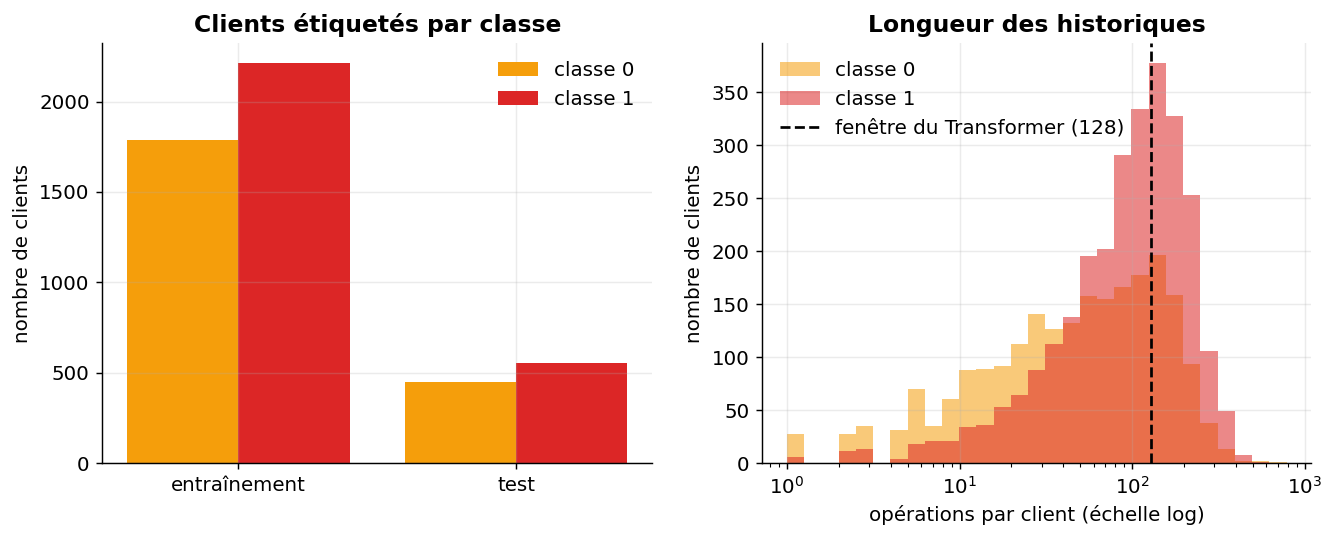

*Figure — À gauche, les clients étiquetés par classe dans l'entraînement et le test : les proportions doivent être proches. À droite, le nombre d'opérations par client, par classe (échelle log). Au-delà du pointillé, le Transformer ne lit que les 128 dernières opérations.*

In [11]:
if PHASE == "public":
    display(describe_split(events, clients, split))
    plot_data_overview(events, clients, split, "data_overview")
    preview(events)
    preview(clients.reset_index())

### Données internes : colonnes attendues

`PRIVATE_COLUMNS` liste les colonnes attendues, avec leur description. La correspondance avec les vrais noms des colonnes est faite par la cellule `PRIVATE_CONFIG`. Les deux autres constantes règlent la taille et les modalités du **jeu factice**, qui sert seulement à vérifier que tout s'exécute.

In [12]:
PRIVATE_COLUMNS = {
    "client_id": "Identifiant client pseudonymisé",
    "event_time": "Horodatage de l'opération",
    "amount": "Montant signé",
    "event_type": "Type d'opération (carte, virement, prélèvement…)",
    "merchant_category": "Catégorie du commerçant ou de la contrepartie",
    "channel": "Canal (agence, mobile, internet…)",
    "target": "1 si le client souscrit le produit dans le mois suivant la date de coupure, sinon 0 ; vide si inconnu",
    "cutoff_date": "Date de coupure de l'observation",
}
N_FAKE_EVENTS = 27_000  # ≈ 900 clients factices de 30 opérations : plus de 100 clients au test
FAKE_MERCHANTS = ["alimentation", "restauration", "transport", "habillement", "energie", "telecom",
                  "voyage", "loisirs", "salaire", "loyer", "epargne"]  # catégories de commerçant factices

### Fabrication du jeu factice

`make_fake_data` fabrique un jeu **factice** au même format : environ 900 clients, avec des paiements par carte, des virements, des prélèvements, des retraits et des dépôts. Il ne contient aucune donnée réelle, mais il comporte :
- une **propension cachée** par client, qui oriente ses virements, son canal et sa cible : il y a donc un signal à apprendre ;
- quelques opérations **après** la coupure, que la règle point-in-time doit écarter ;
- 5 % de clients sans étiquette, utilisés seulement pour le pré-entraînement.

In [13]:
def make_fake_data(n: int) -> pd.DataFrame:
    """Fabrique `n` opérations factices au format des données internes (aucune donnée réelle).

    Une propension cachée par client oriente ses virements, son canal mobile et sa cible.
    """
    rng = np.random.default_rng(SEED)
    n_clients = max(n // 30, 50)
    propensity = rng.normal(size=n_clients)
    cutoffs = pd.Timestamp("2025-02-01") + pd.to_timedelta(rng.integers(0, 330, n_clients), unit="D")
    owner = rng.integers(0, n_clients, n)
    tilt = 1 / (1 + np.exp(-propensity[owner]))  # entre 0 et 1, croît avec la propension
    other_types = rng.choice(["carte", "prelevement", "retrait", "depot"], size=n, p=[0.6, 0.15, 0.1, 0.15])
    event_type = np.where(rng.random(n) < 0.05 + 0.25 * tilt, "virement", other_types)
    channel = np.where(rng.random(n) < 0.15 + 0.4 * tilt, "mobile",
                       rng.choice(["agence", "internet", "distributeur"], size=n))
    magnitude = np.round(rng.lognormal(mean=3.5, sigma=1.0, size=n), 2)
    offset_days = rng.uniform(-10, 240, size=n)  # quelques opérations après la coupure, à écarter
    target = (rng.random(n_clients) < 1 / (1 + np.exp(-(1.5 * propensity - 0.8)))).astype(float)
    target[rng.random(n_clients) < 0.05] = np.nan  # clients sans étiquette
    return pd.DataFrame({
        "client_id": np.array([f"C{index:06d}" for index in range(n_clients)])[owner],
        "event_time": (cutoffs[owner] - pd.to_timedelta(offset_days, unit="D")).round("s"),
        "amount": np.where(event_type == "depot", magnitude, -magnitude),
        "event_type": event_type,
        "merchant_category": rng.choice(FAKE_MERCHANTS, size=n),
        "channel": channel,
        "target": target[owner],
        "cutoff_date": cutoffs[owner].strftime("%Y-%m-%d"),
    })

### Chargement et mêmes transformations

Ce code ne s'exécute qu'en phase `private`. Il appelle les mêmes fonctions que pour le jeu public, avec une seule différence : le test est **hors période**. Il réunit les coupures les plus récentes, et le pré-entraînement ne voit aucun client de cette période. Aucune ligne brute n'est affichée : `preview` ne montre que la structure, et le tableau ne donne que des effectifs.

In [14]:
if PHASE == "private":
    raw_private = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=N_FAKE_EVENTS)
    missing = set(PRIVATE_COLUMNS) - set(raw_private.columns)
    assert not missing, f"colonnes manquantes : {missing}"
    raw_private["client_id"] = raw_private["client_id"].astype(str)
    raw_private = keep_sample(raw_private, N_CLIENTS, SEED)
    events, clients = finalize_tables(raw_private)
    clients, classes = encode_target(clients)
    # Test hors période : coupures les plus récentes, jamais vues au pré-entraînement
    split = split_clients(clients, out_of_time=True, seed=SEED)
    print(f"{len(events):,} opérations antérieures aux coupures, {len(clients):,} clients ; classes : {classes}")
    display(describe_split(events, clients, split))
    plot_data_overview(events, clients, split, "data_overview_private")
    preview(events)
    del raw_private

## 3. L'approche de référence

### Protocole commun : budgets d'étiquettes et tirages appariés

On simule une équipe qui ne dispose que de quelques centaines d'étiquettes, puis de toutes :
- pour chaque **budget**, `N_DRAWS` tirages stratifiés de clients d'entraînement ;
- dans chaque tirage, 15 % du budget sert de **validation** pour l'arrêt précoce ;
- les tirages sont **appariés** : XGBoost, Transformer et fusion voient exactement les mêmes clients, ce qui rend les écarts directement comparables.

In [15]:
BUDGETS = by_scale(reduced=[200, 500, None], full=[500, 1500, None])  # étiquettes d'entraînement ; None = toutes
N_DRAWS = by_scale(reduced=2, full=5)  # tirages appariés par budget
VALIDATION_FRACTION = 0.15  # part du budget réservée à l'arrêt précoce
MAIN_BUDGET = by_scale(reduced=500, full=1500)  # budget rapporté dans le tableau de synthèse

CLIENT_INDEX = clients.index  # ordre de référence des lignes de toutes les matrices
LABELS = clients["target"].to_numpy(dtype=float)  # NaN pour les clients sans étiquette
TRAIN_ROWS = CLIENT_INDEX.get_indexer(split["train"])
TEST_ROWS = CLIENT_INDEX.get_indexer(split["test"])
PRETRAIN_ROWS = CLIENT_INDEX.get_indexer(split["pretrain"])
Y_TEST = LABELS[TEST_ROWS].astype(int)
assert len(TEST_ROWS) >= 100 and 0 < Y_TEST.sum() < len(Y_TEST), "test trop petit ou à une seule classe"


def make_cells() -> list[dict]:
    """Tire, pour chaque budget et chaque tirage, les clients d'ajustement et de validation."""
    cells = []
    budgets = [budget for budget in BUDGETS if budget is None or budget < len(TRAIN_ROWS)]
    train_labels = LABELS[TRAIN_ROWS].astype(int)
    for budget_index, budget in enumerate(budgets):
        for draw in range(N_DRAWS):
            cell_seed = SEED + 1000 * budget_index + draw
            chosen = TRAIN_ROWS if budget is None else train_test_split(
                TRAIN_ROWS, train_size=budget, stratify=train_labels, random_state=cell_seed)[0]
            fit_rows, val_rows = train_test_split(
                chosen, test_size=VALIDATION_FRACTION, stratify=LABELS[chosen], random_state=cell_seed)
            cells.append({"budget": "toutes" if budget is None else str(budget), "n_labels": len(chosen),
                          "draw": draw, "seed": cell_seed, "fit_rows": fit_rows, "val_rows": val_rows})
    return cells


CELLS = make_cells()
BUDGET_LABELS = list(dict.fromkeys(cell["budget"] for cell in CELLS))
MAIN_LABEL = str(MAIN_BUDGET) if str(MAIN_BUDGET) in BUDGET_LABELS else BUDGET_LABELS[0]
print(f"Budget rapporté dans la synthèse : {MAIN_LABEL} étiquettes")
display(pd.DataFrame(CELLS).groupby("budget", sort=False).agg(tirages=("draw", "count"), etiquettes=("n_labels", "first")))

Budget rapporté dans la synthèse : 1500 étiquettes


,tirages,etiquettes
budget,,
500,5,500
1500,5,1500
toutes,5,4000


### Vocabulaires des agrégats et des séquences

Les modalités détaillées (types d'opération, commerçants, canaux, couples de transitions) sont choisies par **fréquence sur le réservoir de pré-entraînement**. Le test n'y entre jamais, et l'étiquette n'est jamais regardée. Les modalités rares sont regroupées sous « autre » dans les agrégats. Dans le Transformer, elles reçoivent l'indice « inconnu ».

In [16]:
WINDOWS_DAYS = (30, 60)  # fenêtres récentes des agrégats, en jours avant la coupure
TOP_EVENT_TYPES = 15  # types d'opération détaillés ; les autres sont regroupés
TOP_MERCHANTS = 20  # catégories de commerçant détaillées
TOP_CHANNELS = 8  # canaux détaillés
TOP_TRANSITIONS = 30  # couples « type A suivi de type B » comptés
TRANSITION_GAPS_HOURS = (1, 24)  # délais maximaux entre A et B, comme dans la source
MIN_COUNT = 20  # fréquence minimale d'une modalité pour être détaillée dans les agrégats
MIN_TOKEN_COUNT = 5  # fréquence minimale d'une modalité pour avoir son propre embedding


def frequent_values(values: pd.Series, min_count: int, max_size: int | None = None) -> list[str]:
    """Modalités d'au moins `min_count` occurrences, de la plus à la moins fréquente."""
    counts = values.value_counts()
    return counts[counts >= min_count].index[:max_size].tolist()


def build_vocabularies(pool_events: pd.DataFrame) -> dict[str, list[str]]:
    """Vocabulaires appris sur le seul réservoir de pré-entraînement, sans étiquette."""
    previous_type = pool_events.groupby("client_id")["event_type"].shift()
    pairs = (previous_type + ">" + pool_events["event_type"]).dropna()
    return {
        "aggregate_event_type": frequent_values(pool_events["event_type"], MIN_COUNT, TOP_EVENT_TYPES),
        "aggregate_merchant_category": frequent_values(pool_events["merchant_category"], MIN_COUNT, TOP_MERCHANTS),
        "aggregate_channel": frequent_values(pool_events["channel"], MIN_COUNT, TOP_CHANNELS),
        "transitions": frequent_values(pairs, MIN_COUNT, TOP_TRANSITIONS),
        "event_type": frequent_values(pool_events["event_type"], MIN_TOKEN_COUNT),
        "merchant_category": frequent_values(pool_events["merchant_category"], MIN_TOKEN_COUNT),
        "channel": frequent_values(pool_events["channel"], MIN_TOKEN_COUNT),
    }


VOCABULARIES = build_vocabularies(events[events["client_id"].isin(split["pretrain"])])
display(pd.Series({name: len(values) for name, values in VOCABULARIES.items()}, name="modalités").to_frame())

,modalités
aggregate_event_type,10
aggregate_merchant_category,20
aggregate_channel,6
transitions,30
event_type,10
merchant_category,239
channel,6


### Agrégats par modalité et compteurs de transitions

- `category_aggregates` : **nombre, somme et moyenne** des montants par modalité (type, commerçant, canal).
- `transition_counts` : nombre de fois où un type B **suit** un type A en moins de 1 h ou de 24 h, comme dans la source.

Sur le jeu public, les dates sont au jour près. « Moins de 1 h » y veut donc dire « le même jour », et « moins de 24 h » inclut le lendemain.

In [17]:
def category_aggregates(base: pd.DataFrame, column: str, kept: list[str]) -> pd.DataFrame:
    """Nombre, somme et moyenne des montants par modalité de `column` (modalités rares regroupées)."""
    category = base[column].where(base[column].isin(kept), "autre")
    table = base.assign(category=category).groupby(["client_id", "category"])["amount"].agg(["size", "sum", "mean"])
    table = table.unstack("category")
    table.columns = [f"{column}_{stat}_{value}" for stat, value in table.columns]
    return table


def transition_counts(base: pd.DataFrame, kept_pairs: list[str]) -> pd.DataFrame:
    """Compteurs de transitions : combien de fois le type B suit le type A en moins de 1 h ou de 24 h."""
    by_client = base.groupby("client_id")
    pair = by_client["event_type"].shift() + ">" + base["event_type"]
    gap_hours = by_client["event_time"].diff().dt.total_seconds() / 3600
    frames = []
    for max_gap in TRANSITION_GAPS_HOURS:
        mask = pair.isin(kept_pairs) & (gap_hours <= max_gap)
        counts = pd.crosstab(base.loc[mask, "client_id"], pair[mask])
        counts.columns = [f"transition_{max_gap}h_{value}" for value in counts.columns]
        frames.append(counts)
    return pd.concat(frames, axis=1)

### La table d'agrégats

Une ligne par client avec :
- les volumes et montants globaux ;
- les mêmes sur les 30 et 60 jours avant la coupure ;
- les agrégats par modalité et les compteurs de transitions.

C'est l'entrée du XGBoost, et aussi la branche tabulaire du réseau (« joint fusion »). L'étiquette n'intervient pas dans le calcul : on peut le faire une fois pour tous les clients.

In [18]:
def build_aggregates(events: pd.DataFrame, clients: pd.DataFrame, vocabularies: dict) -> pd.DataFrame:
    """Une ligne d'agrégats par client, calculée sans étiquette sur les opérations antérieures à la coupure."""
    age_days = (events["client_id"].map(clients["cutoff_date"]) - events["event_time"]).dt.total_seconds() / 86400
    base = events.assign(age_days=age_days, abs_amount=events["amount"].abs())
    grouped = base.groupby("client_id")
    features = pd.DataFrame({
        "n_events": grouped.size(),
        "amount_sum": grouped["amount"].sum(),
        "amount_mean": grouped["amount"].mean(),
        "amount_std": grouped["amount"].std(),
        "abs_amount_max": grouped["abs_amount"].max(),
        "history_days": grouped["age_days"].max(),
        "days_since_last": grouped["age_days"].min(),
    })
    for window in WINDOWS_DAYS:
        recent = base[base["age_days"] <= window].groupby("client_id")
        features[f"n_events_{window}d"] = recent.size()
        features[f"amount_sum_{window}d"] = recent["amount"].sum()
        features[f"abs_amount_mean_{window}d"] = recent["abs_amount"].mean()
    for column in ["event_type", "merchant_category", "channel"]:
        features = features.join(category_aggregates(base, column, vocabularies[f"aggregate_{column}"]))
    features = features.join(transition_counts(base, vocabularies["transitions"]))
    # Aucune opération dans une fenêtre ou une modalité = 0 ; écart-type d'une seule opération = 0
    return features.reindex(clients.index).fillna(0.0)


FEATURES = build_aggregates(events, clients, VOCABULARIES)
FEATURES_MATRIX = FEATURES.to_numpy(dtype=np.float32)
print(f"{FEATURES.shape[0]:,} clients × {FEATURES.shape[1]} agrégats")

5,000 clients × 184 agrégats


### XGBoost de référence

Réglages du plan : 300 arbres au plus, profondeur 4, pas de 0,05, sous-échantillonnage de 0,8. L'**arrêt précoce** cesse d'ajouter des arbres quand l'AUC de validation ne progresse plus depuis 30 arbres. La référence ne s'en trouve ni sous-entraînée ni sur-ajustée.

`fast_auc` calcule l'AUC par les rangs, assez vite pour les milliers de tirages du bootstrap : $\text{AUC} = \frac{\sum R_+ - n_+(n_+ + 1)/2}{n_+ \, n_-}$, où $R_+$ désigne les rangs des positifs.

In [19]:
from xgboost import XGBClassifier

XGB_PARAMS = {
    "n_estimators": 300,  # nombre maximal d'arbres ; l'arrêt précoce choisit le nombre utile
    "max_depth": 4,  # arbres peu profonds : robustes avec peu d'étiquettes
    "learning_rate": 0.05,  # pas modeste, compensé par le nombre d'arbres
    "subsample": 0.8,  # chaque arbre voit 80 % des clients : régularise
    "colsample_bytree": 0.8,  # et 80 % des agrégats
    "tree_method": "hist",  # algorithme rapide par histogrammes
    "eval_metric": "auc",  # critère suivi sur la validation
    "early_stopping_rounds": 30,  # arrêt si l'AUC de validation stagne pendant 30 arbres
    "n_jobs": 4,  # cœurs de calcul
}


def train_xgboost(fit_rows: np.ndarray, val_rows: np.ndarray, seed: int) -> XGBClassifier:
    """Entraîne le XGBoost de référence avec arrêt précoce sur la validation du tirage."""
    model = XGBClassifier(**XGB_PARAMS, random_state=seed)
    model.fit(FEATURES_MATRIX[fit_rows], LABELS[fit_rows].astype(int),
              eval_set=[(FEATURES_MATRIX[val_rows], LABELS[val_rows].astype(int))], verbose=False)
    return model


def fast_auc(y_true: np.ndarray, scores: np.ndarray) -> float:
    """AUC par la statistique de Mann-Whitney (NaN si une seule classe est présente)."""
    y_true = np.asarray(y_true).astype(int)
    n_positive = int(y_true.sum())
    n_negative = len(y_true) - n_positive
    if n_positive == 0 or n_negative == 0:
        return float("nan")
    ranks = rankdata(scores)
    return float((ranks[y_true == 1].sum() - n_positive * (n_positive + 1) / 2) / (n_positive * n_negative))

### Entraînement sur tous les budgets et tous les tirages

Un modèle est entraîné pour chaque couple (budget, tirage), et ses scores de test sont gardés pour l'évaluation. La colonne « arbres retenus » montre l'effet de l'arrêt précoce. Le modèle du budget principal (premier tirage) est conservé pour mesurer la latence.

In [20]:
TEST_SCORES = {"xgboost": {}, "sequence": {}, "fusion": {}}  # scores de test par (budget, tirage)
xgboost_log = []
for cell in CELLS:
    key = (cell["budget"], cell["draw"])
    model = train_xgboost(cell["fit_rows"], cell["val_rows"], cell["seed"])
    TEST_SCORES["xgboost"][key] = model.predict_proba(FEATURES_MATRIX[TEST_ROWS])[:, 1]
    if key == (MAIN_LABEL, 0):
        main_xgboost = model  # gardé pour la mesure de latence
    xgboost_log.append({"budget": cell["budget"], "tirage": cell["draw"], "arbres retenus": int(model.best_iteration) + 1,
                        "AUC test": round(fast_auc(Y_TEST, TEST_SCORES["xgboost"][key]), 4)})
display(pd.DataFrame(xgboost_log))

,budget,tirage,arbres retenus,AUC test
0,500,0,101,0.7965
1,500,1,72,0.7975
2,500,2,2,0.7962
3,500,3,5,0.7842
4,500,4,13,0.8187
5,1500,0,59,0.8236
6,1500,1,56,0.8190
7,1500,2,126,0.8212
8,1500,3,109,0.8245
9,1500,4,87,0.8179


## 4. La nouvelle approche

### Fidélité à la source et réglages

Cette partie reprend la méthode TBS de la source, décrite dans « comment ça marche » : une branche séquence, puis une fusion des rangs.
- **Réseau** : Transformer d'environ 0,4 M de paramètres qui lit les 128 dernières opérations, pré-entraîné sur le jeu lui-même, comme dans la source.
- **Pré-entraînement** : **modélisation d'opérations masquées**. On cache 15 % des opérations et le réseau doit retrouver leur type et leur catégorie de commerçant. La source compare plusieurs objectifs ; nous gardons le plus simple.
- **Ajustement « joint fusion »** : l'état résumé de la séquence et les agrégats passent ensemble dans la tête de classification.
- **Fusion** : moyenne des rangs, sans poids à régler.

**Écarts** : XGBoost au lieu de LightGBM, comme le prévoit le plan. Aucun hyperparamètre n'est réglé, comme dans la source. Le réservoir de pré-entraînement **exclut les clients du test**, ce qui est plus strict que la source.

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F

D_MODEL = 96  # dimension des représentations (≈ 0,4 M de paramètres au total)
N_HEADS = 4  # têtes d'attention
N_LAYERS = 2  # couches du Transformer
FF_DIM = 512  # largeur du réseau interne de chaque couche
DROPOUT = 0.1  # régularisation par extinction aléatoire de neurones
MASK_RATE = 0.15  # part des opérations masquées au pré-entraînement
PRETRAIN_EPOCHS = by_scale(reduced=1, full=5)  # passes de pré-entraînement sans étiquette
FINETUNE_EPOCHS = by_scale(reduced=3, full=10)  # passes d'ajustement sur l'étiquette
LEARNING_RATE = 1e-3  # taux d'apprentissage d'AdamW, valeur du plan
WEIGHT_DECAY = 0.01  # pénalité sur les poids d'AdamW
BATCH_SIZE = 64  # clients par lot
PAD, UNKNOWN, MASK = 0, 1, 2  # indices réservés : remplissage, modalité inconnue, opération masquée
N_SPECIAL = 3  # nombre d'indices réservés
DEVICE = device()
USE_AMP = DEVICE == "cuda"  # précision mixte (float16) seulement sur GPU
print(f"Matériel : {DEVICE} ; précision mixte : {USE_AMP} ; torch {torch.__version__}")

Matériel : cuda ; précision mixte : True ; torch 2.14.1+cu130


### Encodage des séquences

Chaque client devient un tableau d'au plus 128 opérations, les plus récentes, alignées à gauche et complétées par un jeton de remplissage (`PAD`). Chaque opération porte :
- 3 indices catégoriels (type, commerçant, canal), transformés en embeddings ;
- le **montant en log signé**, $\text{sign}(x)\log(1+|x|)$, standardisé : les montants extrêmes sont comprimés et le sens débit / crédit est préservé ;
- le **délai depuis l'opération précédente**, $\log(1+\text{jours})$.

In [22]:
def encode_column(values: pd.Series, vocabulary: list[str]) -> np.ndarray:
    """Remplace chaque modalité par son indice d'embedding (UNKNOWN si rare ou inconnue)."""
    mapping = {value: index + N_SPECIAL for index, value in enumerate(vocabulary)}
    return values.map(mapping).fillna(UNKNOWN).to_numpy(dtype=np.int64)


def signed_log(values) -> np.ndarray:
    """Logarithme signé : comprime les montants extrêmes sans perdre le sens débit / crédit."""
    values = np.asarray(values, dtype=np.float64)
    return np.sign(values) * np.log1p(np.abs(values))


def build_sequences(events: pd.DataFrame, client_index: pd.Index, vocabularies: dict,
                    amount_stats: tuple[float, float]) -> dict[str, torch.Tensor]:
    """Tenseurs des MAX_EVENTS dernières opérations de chaque client, alignées à gauche, complétées par PAD."""
    frame = events[events["client_id"].isin(client_index)].copy()
    frame["gap_days"] = frame.groupby("client_id")["event_time"].diff().dt.total_seconds().fillna(0.0) / 86400
    frame = frame[frame.groupby("client_id").cumcount(ascending=False) < MAX_EVENTS]  # les plus récentes
    positions = frame.groupby("client_id").cumcount().to_numpy()
    rows = client_index.get_indexer(frame["client_id"])
    shape = (len(client_index), MAX_EVENTS)
    tensors = {}
    for column in ["event_type", "merchant_category", "channel"]:
        array = np.full(shape, PAD, dtype=np.int64)
        array[rows, positions] = encode_column(frame[column], vocabularies[column])
        tensors[column] = torch.from_numpy(array)
    numeric = np.zeros(shape + (2,), dtype=np.float32)
    numeric[rows, positions, 0] = (signed_log(frame["amount"]) - amount_stats[0]) / amount_stats[1]
    numeric[rows, positions, 1] = np.log1p(frame["gap_days"].clip(lower=0).to_numpy())
    tensors["numeric"] = torch.from_numpy(numeric)
    return tensors

### Tenseurs pour tous les clients et longueur des entrées

Séquences et agrégats standardisés sont construits une fois pour tous les clients. Les statistiques de normalisation viennent du **seul réservoir** de pré-entraînement.

La fenêtre de 128 opérations est celle de la source. Le tableau affiche, **par classe**, la part de clients dont l'historique est tronqué. Elle peut dépasser 5 %, mais les agrégats couvrent tout l'historique : les opérations anciennes restent connues de la fusion, et le réseau joint les reçoit aussi sous forme résumée.

In [23]:
pool_amounts = signed_log(events.loc[events["client_id"].isin(split["pretrain"]), "amount"])
AMOUNT_STATS = (float(pool_amounts.mean()), float(pool_amounts.std() + 1e-6))  # réservoir seul
SEQUENCES = build_sequences(events, CLIENT_INDEX, VOCABULARIES, AMOUNT_STATS)


def standardize_aggregates(features: pd.DataFrame, reference_rows: np.ndarray) -> torch.Tensor:
    """Agrégats en log signé puis centrés-réduits sur le réservoir, pour la branche tabulaire du réseau."""
    transformed = signed_log(features.to_numpy())
    mean = transformed[reference_rows].mean(axis=0)
    std = transformed[reference_rows].std(axis=0)
    scaled = (transformed - mean) / np.where(std > 0, std, 1.0)
    return torch.from_numpy(np.clip(scaled, -5, 5).astype(np.float32))


AGGREGATES = standardize_aggregates(FEATURES, PRETRAIN_ROWS)
N_EVENTS_ALL = events.groupby("client_id").size().reindex(CLIENT_INDEX).to_numpy()
print(f"Séquences : {tuple(SEQUENCES['event_type'].shape)} ; agrégats : {tuple(AGGREGATES.shape)}")
truncation = (pd.DataFrame({"classe": LABELS, "tronqué": N_EVENTS_ALL > MAX_EVENTS}).dropna()
              .groupby("classe")["tronqué"].mean().mul(100).round(1))
display(truncation.rename(f"clients au-delà de {MAX_EVENTS} opérations (%)").to_frame())

Séquences : (5000, 128) ; agrégats : (5000, 184)


,clients au-delà de 128 opérations (%)
classe,
0.0,21.9
1.0,38.3


### L'encodeur de séquences

Chaque opération devient un vecteur : somme des embeddings de type, de commerçant et de canal, de la projection des deux nombres et d'un embedding de position. Ensuite :
- un **jeton résumé** est placé en position 0, comme le `[CLS]` des modèles de langue ; c'est lui qui représente le client ;
- l'attention ignore les positions de remplissage ;
- chaque bloc est normalisé *avant* son calcul (`norm_first`), ce qui stabilise l'entraînement avec peu de données.

In [24]:
class SequenceEncoder(nn.Module):
    """Petit Transformer sur les opérations d'un client ; la position 0 résume la séquence."""

    def __init__(self, n_types: int, n_merchants: int, n_channels: int):
        """Crée les embeddings (tailles des vocabulaires, indices réservés compris) et les couches d'attention."""
        super().__init__()
        self.type_embedding = nn.Embedding(n_types, D_MODEL, padding_idx=PAD)
        self.merchant_embedding = nn.Embedding(n_merchants, D_MODEL, padding_idx=PAD)
        self.channel_embedding = nn.Embedding(n_channels, D_MODEL, padding_idx=PAD)
        self.numeric_projection = nn.Linear(2, D_MODEL)  # montant et délai
        self.position_embedding = nn.Embedding(MAX_EVENTS + 1, D_MODEL)
        self.summary_token = nn.Parameter(torch.zeros(1, 1, D_MODEL))  # jeton qui résume le client
        layer = nn.TransformerEncoderLayer(D_MODEL, N_HEADS, FF_DIM, DROPOUT, batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, N_LAYERS, enable_nested_tensor=False)
        self.output_norm = nn.LayerNorm(D_MODEL)

    def forward(self, types, merchants, channels, numeric) -> torch.Tensor:
        """Retourne les états (lot, 1 + MAX_EVENTS, D_MODEL) ; la position 0 résume le client."""
        tokens = (self.type_embedding(types) + self.merchant_embedding(merchants)
                  + self.channel_embedding(channels) + self.numeric_projection(numeric))
        summary = self.summary_token.expand(tokens.shape[0], -1, -1)
        tokens = torch.cat([summary, tokens], dim=1)
        tokens = tokens + self.position_embedding(torch.arange(tokens.shape[1], device=tokens.device))
        # Le remplissage est ignoré par l'attention ; le jeton résumé ne l'est jamais
        padding = torch.cat([torch.zeros_like(types[:, :1], dtype=torch.bool), types == PAD], dim=1)
        return self.output_norm(self.transformer(tokens, src_key_padding_mask=padding))

### Les deux têtes du modèle

- **Pré-entraînement** : deux couches linéaires retrouvent, à chaque position masquée, le type d'opération et le commerçant cachés.
- **Classification « joint fusion »** : l'état résumé de la séquence est mis bout à bout avec une petite projection des agrégats, puis un perceptron produit le score. Réseau et agrégats sont ajustés **ensemble** sur l'étiquette.

In [25]:
class SequenceModel(nn.Module):
    """Encodeur + tête de pré-entraînement (opérations masquées) + tête de classification « joint fusion »."""

    def __init__(self, n_types: int, n_merchants: int, n_channels: int, n_aggregates: int):
        """Crée l'encodeur, les deux têtes de reconstruction et la tête de classification sur `n_aggregates` agrégats."""
        super().__init__()
        self.encoder = SequenceEncoder(n_types, n_merchants, n_channels)
        self.type_head = nn.Linear(D_MODEL, n_types)  # retrouve le type d'opération masqué
        self.merchant_head = nn.Linear(D_MODEL, n_merchants)  # et la catégorie de commerçant masquée
        self.aggregate_branch = nn.Sequential(nn.Linear(n_aggregates, 64), nn.GELU(), nn.Dropout(DROPOUT))
        self.classifier = nn.Sequential(nn.Linear(D_MODEL + 64, 64), nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(64, 1))

    def pretraining_logits(self, types, merchants, channels, numeric):
        """Logits de reconstruction (type, commerçant) à chaque position d'opération."""
        hidden = self.encoder(types, merchants, channels, numeric)[:, 1:]
        return self.type_head(hidden), self.merchant_head(hidden)

    def forward(self, types, merchants, channels, numeric, aggregates) -> torch.Tensor:
        """Logit de la classe positive, à partir du résumé de séquence et des agrégats."""
        summary = self.encoder(types, merchants, channels, numeric)[:, 0]
        joint = torch.cat([summary, self.aggregate_branch(aggregates)], dim=1)
        return self.classifier(joint).squeeze(-1)


def build_model() -> SequenceModel:
    """Instancie le modèle aux tailles des vocabulaires et des agrégats, sur le matériel de calcul."""
    sizes = [len(VOCABULARIES[column]) + N_SPECIAL for column in ["event_type", "merchant_category", "channel"]]
    return SequenceModel(*sizes, n_aggregates=AGGREGATES.shape[1]).to(DEVICE)

### Lots et masquage

- `batch_inputs` extrait les tenseurs d'un lot de clients.
- `shuffled_batches` mélange les clients de façon **reproductible** : générateur initialisé avec la graine.
- `mask_events` cache 15 % des opérations réelles (jamais le remplissage). Les positions non masquées reçoivent la cible `-100`, que la perte ignore.

In [26]:
def batch_inputs(rows: np.ndarray) -> list[torch.Tensor]:
    """Entrées (types, commerçants, canaux, nombres, agrégats) des clients `rows`, encore sur le CPU."""
    index = torch.as_tensor(rows, dtype=torch.long)
    tensors = [SEQUENCES[name][index] for name in ["event_type", "merchant_category", "channel", "numeric"]]
    return tensors + [AGGREGATES[index]]


def shuffled_batches(rows: np.ndarray, generator: torch.Generator) -> list[np.ndarray]:
    """Découpe `rows` en lots de BATCH_SIZE après un mélange reproductible."""
    order = torch.randperm(len(rows), generator=generator).numpy()
    return [rows[order[start:start + BATCH_SIZE]] for start in range(0, len(rows), BATCH_SIZE)]


def mask_events(types: torch.Tensor, merchants: torch.Tensor, generator: torch.Generator):
    """Masque MASK_RATE des opérations réelles ; retourne entrées masquées et cibles (-100 = ignorée)."""
    chosen = (torch.rand(types.shape, generator=generator) < MASK_RATE) & (types != PAD)
    type_targets = torch.where(chosen, types, torch.full_like(types, -100))
    merchant_targets = torch.where(chosen, merchants, torch.full_like(merchants, -100))
    return types.masked_fill(chosen, MASK), merchants.masked_fill(chosen, MASK), type_targets, merchant_targets

### Pas d'optimisation et précision mixte

Un pas d'optimisation enchaîne trois étapes : rétropropagation, **écrêtage du gradient** (sa norme est plafonnée à 1, ce qui évite les sauts brutaux) et mise à jour AdamW. Sur GPU, le calcul passe en **précision mixte** (float16), avec un facteur d'échelle qui protège les petits gradients. Sur CPU, ces deux mécanismes sont inactifs.

In [27]:
def optimizer_step(loss: torch.Tensor, model: nn.Module, optimizer, scaler) -> None:
    """Rétropropagation (mise à l'échelle en précision mixte), écrêtage du gradient, mise à jour."""
    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()


def autocast():
    """Contexte de précision mixte (float16) sur GPU ; sans effet sur CPU."""
    return torch.autocast(device_type="cuda" if USE_AMP else "cpu", enabled=USE_AMP)


def make_scaler():
    """Facteur d'échelle des gradients pour la précision mixte (neutre sans GPU)."""
    return torch.amp.GradScaler("cuda", enabled=USE_AMP)

### Pré-entraînement sans étiquette

Le réseau apprend à **retrouver les opérations masquées** à partir de leur contexte : ce qui précède et ce qui suit, les montants, les délais. Il n'utilise aucune étiquette, et donc tous les clients du réservoir, y compris ceux sans cible. La perte est la somme de deux entropies croisées : type d'opération et commerçant.

In [28]:
def pretrain(model: SequenceModel, rows: np.ndarray, epochs: int, seed: int) -> pd.DataFrame:
    """Pré-entraîne l'encodeur sans étiquette ; retourne la perte moyenne par époque."""
    set_seed(seed)
    generator = torch.Generator().manual_seed(seed)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scaler = make_scaler()
    history = []
    for epoch in range(epochs):
        model.train()
        losses = []
        for batch in shuffled_batches(rows, generator):
            types, merchants, channels, numeric, _ = batch_inputs(batch)
            types, merchants, type_targets, merchant_targets = mask_events(types, merchants, generator)
            if int((type_targets != -100).sum()) == 0:
                continue  # lot sans opération masquée : rien à apprendre
            inputs = [tensor.to(DEVICE) for tensor in (types, merchants, channels, numeric)]
            with autocast():
                type_logits, merchant_logits = model.pretraining_logits(*inputs)
            loss = (F.cross_entropy(type_logits.flatten(0, 1).float(), type_targets.flatten().to(DEVICE), ignore_index=-100)
                    + F.cross_entropy(merchant_logits.flatten(0, 1).float(), merchant_targets.flatten().to(DEVICE),
                                      ignore_index=-100))
            optimizer_step(loss, model, optimizer, scaler)
            losses.append(loss.item())
        history.append({"époque": epoch + 1, "perte de reconstruction": round(float(np.mean(losses)), 4)})
    return pd.DataFrame(history)

### Lancement du pré-entraînement et contrôle sur un client réel

On affiche le modèle réellement évalué (architecture, nombre de paramètres, matériel), puis on pré-entraîne **une seule fois**. Les poids obtenus sont le point de départ commun de tous les ajustements. Un appel sur un vrai client d'entraînement vérifie que le modèle rend un score fini.

In [29]:
set_seed(SEED)
pretrained_model = build_model()
n_parameters = sum(parameter.numel() for parameter in pretrained_model.parameters())
print(f"Modèle évalué : Transformer de séquences ({N_LAYERS} couches, {N_HEADS} têtes, dimension {D_MODEL}), "
      f"{n_parameters / 1e6:.2f} M de paramètres, sur {DEVICE}")
pretrain_durations = []
with timer(pretrain_durations):
    pretrain_history = pretrain(pretrained_model, PRETRAIN_ROWS, PRETRAIN_EPOCHS, SEED)
display(pretrain_history)
print(f"Pré-entraînement sur {len(PRETRAIN_ROWS):,} clients sans étiquette : {pretrain_durations[0] / 1000:.1f} s")
PRETRAINED_STATE = copy.deepcopy(pretrained_model.state_dict())

# Contrôle : un score fini pour un vrai client d'entraînement
pretrained_model.eval()
with torch.no_grad():
    check_logit = pretrained_model(*[tensor.to(DEVICE) for tensor in batch_inputs(TRAIN_ROWS[:1])])
assert check_logit.shape == (1,) and bool(torch.isfinite(check_logit).all()), "sortie du réseau invalide"
del pretrained_model
gc.collect()

Modèle évalué : Transformer de séquences (2 couches, 4 têtes, dimension 96), 0.36 M de paramètres, sur cuda


,époque,perte de reconstruction
0,1,4.2752
1,2,3.4867
2,3,3.3396
3,4,3.2425
4,5,3.1940


Pré-entraînement sur 4,000 clients sans étiquette : 11.7 s


35

### Ajustement sur l'étiquette

Pour chaque tirage, on repart des poids pré-entraînés et on ajuste **tout le réseau**, encodeur compris, avec une entropie croisée binaire. Après chaque époque, l'AUC est mesurée sur la validation du tirage, et l'on garde l'époque la meilleure (**arrêt précoce**, comme pour le XGBoost).

In [30]:
@torch.no_grad()
def predict_sequence(model: SequenceModel, rows: np.ndarray, batch_size: int = 256) -> np.ndarray:
    """Probabilités prédites par le réseau pour les clients `rows`."""
    model.eval()
    outputs = []
    for start in range(0, len(rows), batch_size):
        inputs = [tensor.to(DEVICE) for tensor in batch_inputs(rows[start:start + batch_size])]
        with autocast():
            logits = model(*inputs)
        outputs.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(outputs)


def finetune(fit_rows: np.ndarray, val_rows: np.ndarray, seed: int) -> tuple[SequenceModel, float]:
    """Ajuste le réseau pré-entraîné sur l'étiquette ; garde l'époque de meilleure AUC de validation."""
    set_seed(seed)
    model = build_model()
    model.load_state_dict(PRETRAINED_STATE)
    generator = torch.Generator().manual_seed(seed)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scaler = make_scaler()
    best_auc, best_state = -1.0, None
    for _ in range(FINETUNE_EPOCHS):
        model.train()
        for batch in shuffled_batches(fit_rows, generator):
            inputs = [tensor.to(DEVICE) for tensor in batch_inputs(batch)]
            targets = torch.as_tensor(LABELS[batch], dtype=torch.float32, device=DEVICE)
            with autocast():
                logits = model(*inputs)
            loss = F.binary_cross_entropy_with_logits(logits.float(), targets)
            optimizer_step(loss, model, optimizer, scaler)
        val_auc = fast_auc(LABELS[val_rows], predict_sequence(model, val_rows))
        if best_state is None or val_auc > best_auc:
            best_auc, best_state = val_auc, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, float(best_auc)

### Fusion des rangs sur tous les budgets et tirages

Pour chaque couple (budget, tirage) :
1. ajustement du réseau sur **les mêmes clients** que le XGBoost ;
2. scores de test du réseau seul (gardés pour l'ablation) ;
3. **fusion** : $s_{\text{fusion}} = \tfrac{1}{2}\big(r_{\text{XGB}}/n + r_{\text{réseau}}/n\big)$, avec $r$ le rang du client parmi les $n$ clients du lot de test.

Le score fusionné classe les clients mais n'est **pas une probabilité**. Il dépend aussi du lot sur lequel les rangs sont calculés.

In [31]:
def rank_fusion(first_scores: np.ndarray, second_scores: np.ndarray) -> np.ndarray:
    """Moyenne des rangs normalisés (dans ]0, 1]) de deux modèles sur le même lot de clients."""
    return (rankdata(first_scores) / len(first_scores) + rankdata(second_scores) / len(second_scores)) / 2


sequence_log = []
for cell in CELLS:
    key = (cell["budget"], cell["draw"])
    elapsed = []
    with timer(elapsed):
        model, val_auc = finetune(cell["fit_rows"], cell["val_rows"], cell["seed"])
    TEST_SCORES["sequence"][key] = predict_sequence(model, TEST_ROWS)
    TEST_SCORES["fusion"][key] = rank_fusion(TEST_SCORES["xgboost"][key], TEST_SCORES["sequence"][key])
    sequence_log.append({"budget": cell["budget"], "tirage": cell["draw"], "AUC validation": round(val_auc, 4),
                         "AUC test (réseau seul)": round(fast_auc(Y_TEST, TEST_SCORES["sequence"][key]), 4),
                         "AUC test (fusion)": round(fast_auc(Y_TEST, TEST_SCORES["fusion"][key]), 4),
                         "durée (s)": round(elapsed[0] / 1000, 1)})
    if key == (MAIN_LABEL, 0):
        main_sequence_model = model  # gardé pour la mesure de latence
    else:
        del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
display(pd.DataFrame(sequence_log))

,budget,tirage,AUC validation,AUC test (réseau seul),AUC test (fusion),durée (s)
0,500,0,0.8009,0.7139,0.7774,1.1
1,500,1,0.7839,0.7406,0.7844,1.2
2,500,2,0.8355,0.7606,0.8027,1.2
3,500,3,0.8470,0.7284,0.7755,0.9
4,500,4,0.7644,0.7521,0.8072,0.9
5,1500,0,0.8134,0.7803,0.8119,2.6
6,1500,1,0.8089,0.7658,0.8034,2.5
7,1500,2,0.8318,0.7810,0.8153,3.0
8,1500,3,0.8268,0.7659,0.8068,2.9
9,1500,4,0.8286,0.7842,0.8168,2.6


## 5. Évaluation

### Métriques

- **AUC ROC** : probabilité qu'un positif soit classé au-dessus d'un négatif (0,5 = hasard).
- **Précision moyenne (AP)** : qualité du haut de la liste ; un score constant obtient le taux de positifs.
- **ECE** (erreur de calibration) : écart moyen entre le score et le taux réel de positifs, par tranche de score, $\text{ECE} = \sum_b \frac{n_b}{n}\,|\bar y_b - \bar s_b|$. Pour la fusion, le score est un rang : son ECE montre qu'il **ne faut pas** le lire comme une probabilité.

In [32]:
from sklearn.metrics import average_precision_score

N_BOOTSTRAP = 1000  # rééchantillonnages du test pour les intervalles à 95 %
ECE_BINS = 10  # tranches de score pour l'erreur de calibration
MIN_GAIN = 0.01  # seuil de l'hypothèse : +1 point d'AUC
APPROACH_NAMES = {"xgboost": "XGBoost sur agrégats", "sequence": "Transformer seul (ablation)",
                  "fusion": "XGBoost + Transformer (fusion des rangs)"}
METRIC_LABELS = {"roc_auc": "AUC ROC", "average_precision": "Précision moyenne (AP)",
                 "auc_gain_vs_baseline": "Gain d'AUC vs XGBoost",
                 "expected_calibration_error": "Erreur de calibration (ECE)"}


def expected_calibration_error(y_true, scores, n_bins: int = ECE_BINS) -> float:
    """ECE : écart moyen, pondéré par effectif, entre score moyen et taux observé de positifs par tranche."""
    y_true = np.asarray(y_true, dtype=float)
    scores = np.clip(np.asarray(scores, dtype=float), 0, 1)
    bins = np.minimum((scores * n_bins).astype(int), n_bins - 1)
    total = 0.0
    for value in np.unique(bins):
        in_bin = bins == value
        total += in_bin.mean() * abs(y_true[in_bin].mean() - scores[in_bin].mean())
    return float(total)

### Moyenne sur les tirages et bootstrap apparié

Chaque métrique est la **moyenne sur les tirages** d'un même budget. Pour son intervalle de confiance, on tire au hasard, avec remise, des clients du test, **les mêmes pour toutes les approches et tous les tirages**. On recalcule la métrique 1 000 fois : la dispersion obtenue montre combien le chiffre dépend de l'échantillon de test. On passe à `bootstrap_ci` les indices des clients ; chaque statistique retrouve ensuite ses scores.

In [33]:
def score_matrix(approach: str, budget: str) -> np.ndarray:
    """Scores de test (clients × tirages) d'une approche pour un budget."""
    return np.column_stack([TEST_SCORES[approach][(budget, draw)] for draw in range(N_DRAWS)])


def mean_over_draws(metric, y_true: np.ndarray, matrix: np.ndarray) -> float:
    """Métrique moyennée sur les tirages appariés (colonnes de `matrix`)."""
    return float(np.mean([metric(y_true, matrix[:, draw]) for draw in range(matrix.shape[1])]))


def bootstrap_statistic(statistic, n: int = N_BOOTSTRAP) -> tuple[float, float, float]:
    """Valeur et intervalle à 95 % d'une statistique `statistic(y, indices)` par bootstrap apparié du test."""
    def on_indices(y_true, indices):
        """Convertit l'échantillon bootstrap (cibles, indices de clients) en tableaux, puis applique `statistic`."""
        return statistic(np.asarray(y_true), np.asarray(indices, dtype=int))
    value, low, high = bootstrap_ci(Y_TEST, np.arange(len(Y_TEST)), on_indices, n=n, seed=SEED)
    return float(value), float(low), float(high)

### AUC par budget et écart apparié au XGBoost

Pour chaque budget : AUC moyenne des trois approches, puis **écart au XGBoost**, en points d'AUC, pour le réseau seul et pour la fusion, avec intervalle bootstrap apparié. C'est la table de l'hypothèse : un gain dont l'intervalle contient zéro n'est pas établi.

In [34]:
def budget_summary(budget: str, n_boot: int) -> dict:
    """AUC moyennes et écarts appariés au XGBoost (avec intervalle bootstrap) pour un budget."""
    matrices = {name: score_matrix(name, budget) for name in TEST_SCORES}
    row = {"budget": budget, "étiquettes": next(cell["n_labels"] for cell in CELLS if cell["budget"] == budget)}
    for name, matrix in matrices.items():
        row[f"AUC {name}"] = round(mean_over_draws(fast_auc, Y_TEST, matrix), 4)
    for name in ["sequence", "fusion"]:
        def gain(y_true, indices, name=name):
            """Écart d'AUC moyen (approche `name` moins XGBoost) sur les clients `indices` du test."""
            return (mean_over_draws(fast_auc, y_true, matrices[name][indices])
                    - mean_over_draws(fast_auc, y_true, matrices["xgboost"][indices]))
        value, low, high = bootstrap_statistic(gain, n=n_boot)
        row[f"gain {name} (pts)"] = round(100 * value, 2)
        row[f"IC95 gain {name} (pts)"] = f"[{100 * low:+.2f} ; {100 * high:+.2f}]"
        row[f"_gain_{name}"] = (value, low, high)  # valeurs brutes pour le verdict et les figures
    return row


BUDGET_TABLE = pd.DataFrame([budget_summary(budget, N_BOOTSTRAP) for budget in BUDGET_LABELS])
display(BUDGET_TABLE.drop(columns=[column for column in BUDGET_TABLE.columns if column.startswith("_")]))

,budget,étiquettes,AUC xgboost,AUC sequence,AUC fusion,gain sequence (pts),IC95 gain sequence (pts),gain fusion (pts),IC95 gain fusion (pts)
0,500,500,0.7986,0.7391,0.7894,-5.95,[-7.64 ; -4.21],-0.92,[-1.80 ; -0.06]
1,1500,1500,0.8213,0.7754,0.8108,-4.58,[-6.10 ; -3.05],-1.04,[-1.79 ; -0.27]
2,toutes,4000,0.8340,0.8110,0.8342,-2.30,[-3.74 ; -0.86],0.03,[-0.67 ; +0.78]


### Latence d'inférence

La latence est mesurée **par client**, en traitant le test par lots de 64, comme un calcul de scores par lot. Les agrégats et les séquences sont déjà construits : on mesure le coût des modèles seuls. La fusion additionne les deux modèles ; le calcul des rangs est négligeable, mais il impose de noter **tout un lot** à la fois.

In [35]:
LATENCY_BATCH = 64  # clients par lot


def per_client_latency(predict, rows: np.ndarray) -> list[float]:
    """Durée par client (ms) de `predict` appliquée lot par lot."""
    durations = []
    for start in range(0, len(rows), LATENCY_BATCH):
        batch = rows[start:start + LATENCY_BATCH]
        elapsed = []
        with timer(elapsed):
            predict(batch)
        durations.append(elapsed[0] / len(batch))
    return durations


xgboost_latency = per_client_latency(lambda rows: main_xgboost.predict_proba(FEATURES_MATRIX[rows]), TEST_ROWS)
sequence_latency = per_client_latency(lambda rows: predict_sequence(main_sequence_model, rows), TEST_ROWS)
fusion_latency = [first + second for first, second in zip(xgboost_latency, sequence_latency)]
LATENCIES = {"xgboost": latency_stats(xgboost_latency), "sequence": latency_stats(sequence_latency),
             "fusion": latency_stats(fusion_latency)}
display(pd.DataFrame(LATENCIES).T.rename(index=APPROACH_NAMES).round(3).rename_axis("ms par client"))

,p50,p95,n
ms par client,,,
XGBoost sur agrégats,0.01,0.02,16.0
Transformer seul (ablation),0.08,0.13,16.0
XGBoost + Transformer (fusion des rangs),0.10,0.15,16.0


### Métriques au budget principal

Pour le tableau de synthèse, chaque approche est résumée **au budget principal** (500 étiquettes à l'échelle réduite, 1 500 à l'échelle complète), en moyenne sur les tirages, avec intervalle bootstrap. Le gain par rapport à elle-même n'a pas de sens pour la référence : sa valeur est `None`. Le prédicteur trivial (score constant) sert de plancher : AUC de 0,5, AP égale au taux de positifs.

In [36]:
def approach_metrics(name: str) -> tuple[dict, dict]:
    """Métriques au budget principal (moyenne des tirages) et leurs intervalles bootstrap appariés."""
    matrix = score_matrix(name, MAIN_LABEL)
    reference = score_matrix("xgboost", MAIN_LABEL)
    statistics = {
        "roc_auc": lambda y, idx: mean_over_draws(fast_auc, y, matrix[idx]),
        "average_precision": lambda y, idx: mean_over_draws(average_precision_score, y, matrix[idx]),
        "expected_calibration_error": lambda y, idx: mean_over_draws(expected_calibration_error, y, matrix[idx]),
    }
    if name != "xgboost":  # l'écart de la référence à elle-même n'est pas une mesure
        statistics["auc_gain_vs_baseline"] = lambda y, idx: (mean_over_draws(fast_auc, y, matrix[idx])
                                                             - mean_over_draws(fast_auc, y, reference[idx]))
    metrics, ci95 = {"auc_gain_vs_baseline": None}, {}
    for key, statistic in statistics.items():
        value, low, high = bootstrap_statistic(statistic)
        metrics[key], ci95[key] = value, [low, high]
    return metrics, ci95


METRICS = {name: approach_metrics(name) for name in ["xgboost", "fusion", "sequence"]}
print(f"Prédicteur trivial (score constant) : AUC = 0,500 ; précision moyenne = {Y_TEST.mean():.3f} "
      "(taux de positifs du test)")
display(pd.DataFrame({APPROACH_NAMES[name]: values[0] for name, values in METRICS.items()}).T.round(4))

Prédicteur trivial (score constant) : AUC = 0,500 ; précision moyenne = 0.553 (taux de positifs du test)


,auc_gain_vs_baseline,roc_auc,average_precision,expected_calibration_error
XGBoost sur agrégats,NaN,0.8213,0.8492,0.0354
XGBoost + Transformer (fusion des rangs),-0.0104,0.8108,0.8419,0.0579
Transformer seul (ablation),-0.0458,0.7754,0.8080,0.0921


### Enregistrement des résultats et figure de synthèse

Les résultats (référence et fusion, mêmes clés de métriques) sont validés puis écrits dans `results_<phase>.json`, avec le jeu, le nombre de clients de test et les latences. Le Transformer seul est cité dans les notes : c'est une ablation, détaillée plus haut et dans l'analyse.

résultats enregistrés : results_public.json


,rôle,Gain d'AUC vs XGBoost,AUC ROC,Précision moyenne (AP),Erreur de calibration (ECE),latence p50 (ms)
approche,,,,,,
XGBoost sur agrégats,référence,—,0.8213 [0.7964 ; 0.8461],0.8492 [0.8183 ; 0.8794],0.03537 [0.03763 ; 0.05843],0.01
XGBoost + Transformer (fusion des rangs),nouvelle,-0.01045 [-0.01791 ; -0.002721],0.8108 [0.7859 ; 0.8374],0.8419 [0.8113 ; 0.8729],0.05788 [0.04886 ; 0.08451],0.10


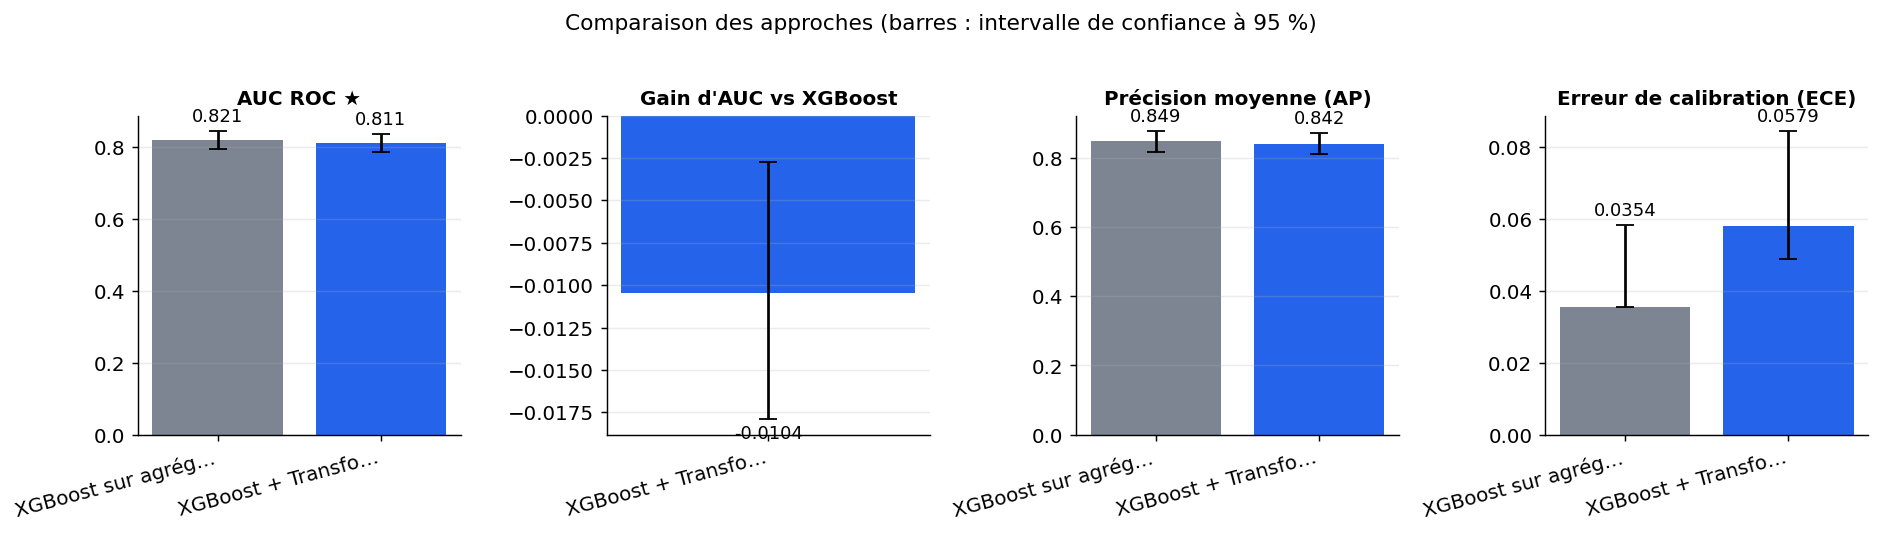

*Figure — Valeur de chaque métrique par approche (★ : métrique principale, à maximiser) ; les barres d'erreur donnent l'intervalle de confiance à 95 % sur 1000 exemples de test.*

In [37]:
if PHASE == "public":
    dataset_info = {"name": HUB_ID, "config": HUB_CONFIG, "split": f"{HUB_SPLIT} (test : {TEST_FRACTION:.0%} des clients étiquetés)"}
else:
    dataset_info = {"name": "données internes", "config": "interne", "split": "test hors période"}
common_note = f"Budget de {MAIN_LABEL} étiquettes, moyenne de {N_DRAWS} tirages appariés ; "
results = save_results({
    "primary_metric": "roc_auc",
    "direction": "max",
    "metric_labels": METRIC_LABELS,
    "dataset": {**dataset_info, "n_examples": int(len(TEST_ROWS))},
    "approaches": [
        {"name": APPROACH_NAMES["xgboost"], "role": "reference", "metrics": METRICS["xgboost"][0],
         "ci95": METRICS["xgboost"][1], "latency_ms": LATENCIES["xgboost"],
         "notes": common_note + f"{FEATURES.shape[1]} agrégats, arrêt précoce sur 15 % du budget."},
        {"name": APPROACH_NAMES["fusion"], "role": "new", "metrics": METRICS["fusion"][0],
         "ci95": METRICS["fusion"][1], "latency_ms": LATENCIES["fusion"],
         "notes": common_note + f"Transformer de {n_parameters / 1e6:.2f} M de paramètres ; rangs calculés sur le lot "
                  f"de test (score non calibré). Transformer seul : AUC {METRICS['sequence'][0]['roc_auc']:.3f}."},
    ],
})
summary_table = results_table(results)
if summary_table is not None:
    display(summary_table)
plot_comparison(results)

### Verdict automatique

Les conclusions s'écrivent d'elles-mêmes à partir des intervalles :
1. **Éligibilité** : la borne basse de l'AUC de chaque approche doit dépasser 0,5, sinon « non concluant ».
2. **Hypothèse** : aux petits budgets, gain médian ≥ +1 point **et** borne basse de chaque gain > 0.
3. **Effet des étiquettes** : le gain avec toutes les étiquettes est-il inférieur aux gains des petits budgets ?

In [38]:
def verdict() -> list[str]:
    """Conclusions automatiques, chacune conditionnée aux intervalles de confiance."""
    messages, eligible = [], True
    for name in ["xgboost", "fusion"]:
        value, low = METRICS[name][0]["roc_auc"], METRICS[name][1]["roc_auc"][0]
        eligible = eligible and low > 0.5
        messages.append(f"{APPROACH_NAMES[name]} : AUC {value:.3f} (borne basse {low:.3f}) → "
                        + ("au-dessus du hasard" if low > 0.5 else "NON CONCLUANT, compatible avec le hasard (0,5)"))
    small = BUDGET_TABLE[BUDGET_TABLE["budget"] != "toutes"]
    gains = list(small["_gain_fusion"])
    if not eligible or not gains:
        messages.append("Hypothèse NON ÉVALUABLE : une approche ne dépasse pas le hasard ou aucun petit budget n'est testé.")
        return messages
    median_gain = float(np.median([gain[0] for gain in gains]))
    supported = median_gain >= MIN_GAIN and all(gain[1] > 0 for gain in gains)
    messages.append(f"Budgets {', '.join(small['budget'])} : gain médian {100 * median_gain:+.2f} pt → hypothèse "
                    + ("SOUTENUE" if supported else "NON SOUTENUE (seuil +1 pt et bornes basses > 0 exigés)"))
    if "toutes" in set(BUDGET_TABLE["budget"]):
        full_gain = BUDGET_TABLE.loc[BUDGET_TABLE["budget"] == "toutes", "_gain_fusion"].iloc[0]
        fades = full_gain[0] < min(gain[0] for gain in gains)
        messages.append(f"Toutes les étiquettes : gain {100 * full_gain[0]:+.2f} pt "
                        f"[{100 * full_gain[1]:+.2f} ; {100 * full_gain[2]:+.2f}] → "
                        + ("le gain diminue, comme dans la source" if fades else "le gain ne diminue pas"))
    return messages


for message in verdict():
    print("•", message)

• XGBoost sur agrégats : AUC 0.821 (borne basse 0.796) → au-dessus du hasard
• XGBoost + Transformer (fusion des rangs) : AUC 0.811 (borne basse 0.786) → au-dessus du hasard
• Budgets 500, 1500 : gain médian -0.98 pt → hypothèse NON SOUTENUE (seuil +1 pt et bornes basses > 0 exigés)
• Toutes les étiquettes : gain +0.03 pt [-0.67 ; +0.78] → le gain ne diminue pas


## 6. Analyse des résultats

### Le gain selon le budget d'étiquettes

- **À gauche** : AUC de test des trois approches selon le nombre d'étiquettes ; les barres vont du pire au meilleur tirage.
- **À droite** : écart d'AUC au XGBoost, avec intervalle bootstrap apparié, pour le réseau seul et pour la fusion.

Si l'idée de la source tient, les points de la fusion sont au-dessus de zéro aux petits budgets et se rapprochent de zéro avec toutes les étiquettes.

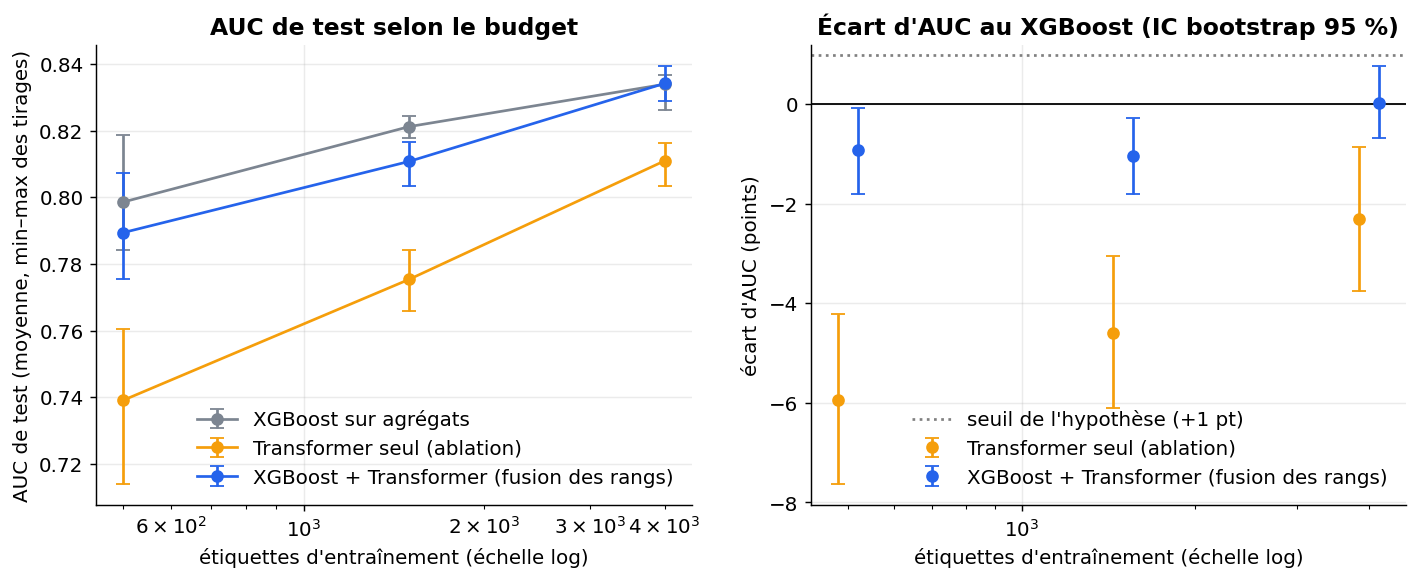

*Figure — À gauche, l'AUC de test des trois approches selon le nombre d'étiquettes (moyenne et étendue des tirages). À droite, l'écart d'AUC au XGBoost avec son intervalle bootstrap apparié : un intervalle qui coupe zéro signifie que le gain n'est pas établi.*

In [39]:
PLOT_COLORS = {"xgboost": COLORS["reference"], "sequence": COLORS["accent"], "fusion": COLORS["new"]}
n_labels = BUDGET_TABLE["étiquettes"].to_numpy(dtype=float)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, color in PLOT_COLORS.items():
    per_draw = np.array([[fast_auc(Y_TEST, TEST_SCORES[name][(budget, draw)]) for draw in range(N_DRAWS)]
                         for budget in BUDGET_LABELS])
    mean = per_draw.mean(axis=1)
    axes[0].errorbar(n_labels, mean, yerr=[mean - per_draw.min(axis=1), per_draw.max(axis=1) - mean],
                     marker="o", capsize=4, color=color, label=APPROACH_NAMES[name])
axes[0].set(xscale="log", title="AUC de test selon le budget", xlabel="étiquettes d'entraînement (échelle log)",
            ylabel="AUC de test (moyenne, min–max des tirages)")
axes[0].legend()
for shift, name in [(0.96, "sequence"), (1.04, "fusion")]:
    gains = 100 * np.array(BUDGET_TABLE[f"_gain_{name}"].tolist())
    axes[1].errorbar(n_labels * shift, gains[:, 0], yerr=[gains[:, 0] - gains[:, 1], gains[:, 2] - gains[:, 0]],
                     marker="o", capsize=4, linestyle="none", color=PLOT_COLORS[name], label=APPROACH_NAMES[name])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].axhline(100 * MIN_GAIN, color="gray", linestyle=":", label="seuil de l'hypothèse (+1 pt)")
axes[1].set(xscale="log", title="Écart d'AUC au XGBoost (IC bootstrap 95 %)",
            xlabel="étiquettes d'entraînement (échelle log)", ylabel="écart d'AUC (points)")
axes[1].legend()
save_figure(fig, "gain_by_budget", "À gauche, l'AUC de test des trois approches selon le nombre d'étiquettes "
            "(moyenne et étendue des tirages). À droite, l'écart d'AUC au XGBoost avec son intervalle bootstrap apparié : "
            "un intervalle qui coupe zéro signifie que le gain n'est pas établi.")

### Diagramme de fiabilité

Par tranche de score, on compare le score moyen au **taux observé de positifs**. Un modèle calibré suit la diagonale. Le XGBoost donne des probabilités, la fusion des rangs : un rang de 0,9 veut dire « dans les 10 % du haut », pas « 90 % de chances ». Si un seuil de décision doit se lire en probabilité, la fusion demande donc une recalibration, par exemple isotone.

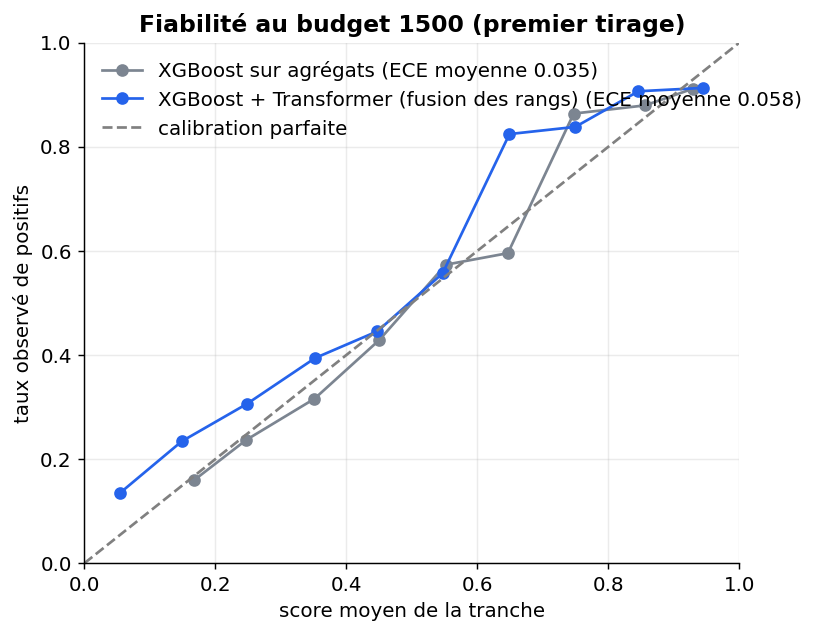

*Figure — Diagramme de fiabilité : par tranche de score, taux réel de positifs. Sur la diagonale, le score se lit comme une probabilité. La fusion produit des rangs, pas des probabilités : son écart à la diagonale est attendu et impose une recalibration avant tout seuil exprimé en probabilité.*

In [40]:
def reliability_curve(y_true: np.ndarray, scores: np.ndarray, n_bins: int = ECE_BINS) -> pd.DataFrame:
    """Score moyen et taux observé de positifs par tranche de score."""
    bins = np.minimum((np.clip(scores, 0, 1) * n_bins).astype(int), n_bins - 1)
    frame = pd.DataFrame({"bin": bins, "y": y_true, "score": scores})
    return frame.groupby("bin").agg(score=("score", "mean"), rate=("y", "mean"), n=("y", "size"))


fig, ax = plt.subplots(figsize=(6.5, 5.2))
for name in ["xgboost", "fusion"]:
    curve = reliability_curve(Y_TEST, score_matrix(name, MAIN_LABEL)[:, 0])
    ece = METRICS[name][0]["expected_calibration_error"]
    ax.plot(curve["score"], curve["rate"], marker="o", color=PLOT_COLORS[name],
            label=f"{APPROACH_NAMES[name]} (ECE moyenne {ece:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="calibration parfaite")
ax.set(xlim=(0, 1), ylim=(0, 1), title=f"Fiabilité au budget {MAIN_LABEL} (premier tirage)",
       xlabel="score moyen de la tranche", ylabel="taux observé de positifs")
ax.legend(loc="upper left")
save_figure(fig, "reliability", "Diagramme de fiabilité : par tranche de score, taux réel de positifs. Sur la diagonale, "
            "le score se lit comme une probabilité. La fusion produit des rangs, pas des probabilités : son écart à la "
            "diagonale est attendu et impose une recalibration avant tout seuil exprimé en probabilité.")

### Performance selon la longueur des historiques

Les clients du test sont répartis en quartiles de nombre d'opérations, et l'AUC est calculée dans chaque groupe au budget principal. On s'attend à ce que le réseau apporte surtout là où la séquence est riche sans dépasser 128 opérations. Si la fusion ne gagne que dans les historiques longs, ou que dans les courts, ce sera visible ici. Les groupes sont petits : ces AUC sont indicatives.

,opérations,clients,positifs,XGBoost sur agrégats,Transformer seul (ablation),XGBoost + Transformer (fusion des rangs)
0,1–37,252,87,0.737,0.713,0.743
1,37–87,252,140,0.863,0.775,0.845
2,87–151,252,163,0.776,0.722,0.761
3,151–784,244,163,0.818,0.776,0.809


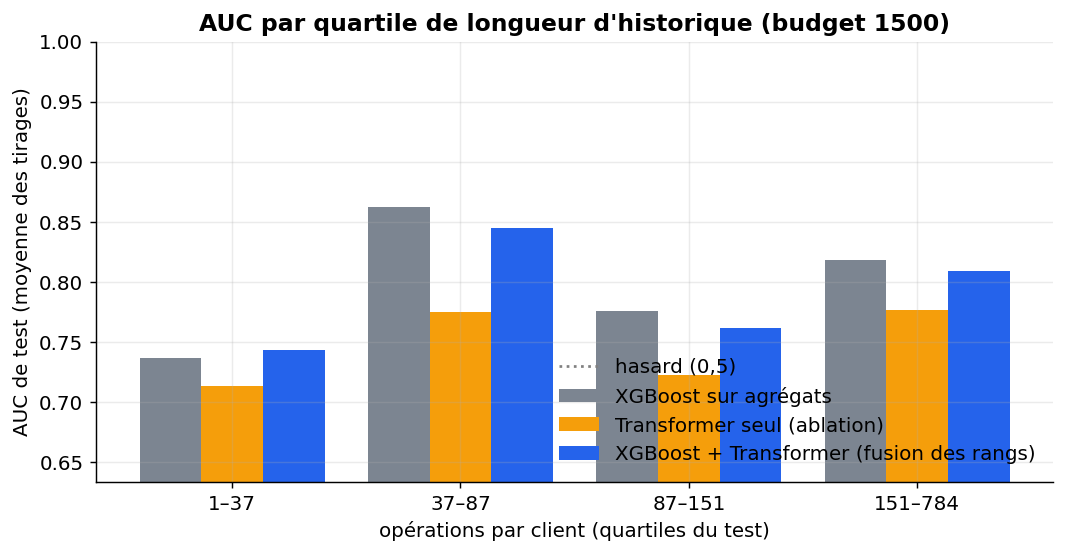

*Figure — AUC de test par quartile du nombre d'opérations par client. Un écart entre les barres orange (fusion) et bleues (XGBoost) qui varie d'un quartile à l'autre indique où le réseau apporte ; chaque groupe ne compte qu'un quart du test, les écarts sont donc fragiles.*

In [41]:
n_events_test = N_EVENTS_ALL[TEST_ROWS]
codes, edges = pd.qcut(n_events_test, q=4, labels=False, retbins=True, duplicates="drop")
rows = []
for code in range(len(edges) - 1):
    in_bin = codes == code
    row = {"opérations": f"{edges[code]:.0f}–{edges[code + 1]:.0f}", "clients": int(in_bin.sum()),
           "positifs": int(Y_TEST[in_bin].sum())}
    for name in PLOT_COLORS:
        row[APPROACH_NAMES[name]] = mean_over_draws(fast_auc, Y_TEST[in_bin], score_matrix(name, MAIN_LABEL)[in_bin])
    rows.append(row)
BY_LENGTH = pd.DataFrame(rows)
display(BY_LENGTH.round(3))

fig, ax = plt.subplots(figsize=(9.5, 4.4))
positions = np.arange(len(BY_LENGTH))
for offset, name in zip([-0.27, 0.0, 0.27], PLOT_COLORS):
    ax.bar(positions + offset, BY_LENGTH[APPROACH_NAMES[name]], width=0.27, color=PLOT_COLORS[name],
           label=APPROACH_NAMES[name])
ax.axhline(0.5, color="gray", linestyle=":", label="hasard (0,5)")
lowest = np.nanmin(BY_LENGTH[[APPROACH_NAMES[name] for name in PLOT_COLORS]].to_numpy())
ax.set_ylim(max(0.0, lowest - 0.08), 1.0)
ax.set_xticks(positions, BY_LENGTH["opérations"])
ax.set(title=f"AUC par quartile de longueur d'historique (budget {MAIN_LABEL})",
       xlabel="opérations par client (quartiles du test)", ylabel="AUC de test (moyenne des tirages)")
ax.legend(loc="lower right")
save_figure(fig, "auc_by_length", "AUC de test par quartile du nombre d'opérations par client. Un écart entre les "
            "barres orange (fusion) et bleues (XGBoost) qui varie d'un quartile à l'autre indique où le réseau apporte ; "
            "chaque groupe ne compte qu'un quart du test, les écarts sont donc fragiles.")

### Complémentarité des deux modèles et exemples d'erreurs

Une fusion n'apporte que si les deux modèles se trompent **sur des clients différents**. La corrélation de rang de Spearman entre leurs scores mesure cette différence : proche de 1, les deux modèles classent pareil et la fusion n'ajoute presque rien. En phase publique seulement, deux tableaux suivent :
- les clients où les deux modèles divergent le plus ;
- les plus grosses erreurs de la fusion : positifs classés en bas, négatifs classés en haut.

Seuls les rangs et quelques agrégats sont montrés.

In [42]:
correlations = [spearmanr(TEST_SCORES["xgboost"][(MAIN_LABEL, draw)], TEST_SCORES["sequence"][(MAIN_LABEL, draw)])[0]
                for draw in range(N_DRAWS)]
print(f"Corrélation de rang XGBoost / réseau au budget {MAIN_LABEL} : {np.mean(correlations):.3f} "
      f"(de {np.min(correlations):.3f} à {np.max(correlations):.3f} selon le tirage)")

if PHASE == "public":
    xgboost_rank = rankdata(score_matrix("xgboost", MAIN_LABEL)[:, 0]) / len(Y_TEST)
    sequence_rank = rankdata(score_matrix("sequence", MAIN_LABEL)[:, 0]) / len(Y_TEST)
    fusion_score = score_matrix("fusion", MAIN_LABEL)[:, 0]
    examples = pd.DataFrame({
        "client_id": CLIENT_INDEX[TEST_ROWS], "cible": Y_TEST,
        "rang XGBoost": xgboost_rank, "rang réseau": sequence_rank, "score fusion": fusion_score,
        "opérations": n_events_test, "historique (jours)": FEATURES["history_days"].to_numpy()[TEST_ROWS],
        "montant total": FEATURES["amount_sum"].to_numpy()[TEST_ROWS],
    })
    examples["désaccord"] = (examples["rang XGBoost"] - examples["rang réseau"]).abs()
    # Erreur de la fusion : un positif classé bas, ou un négatif classé haut
    examples["erreur fusion"] = np.where(Y_TEST == 1, 1 - fusion_score, fusion_score)
    print("Clients où les deux modèles divergent le plus :")
    display(examples.sort_values("désaccord", ascending=False).head(6).round(3))
    print("Plus grosses erreurs de la fusion :")
    display(examples.sort_values("erreur fusion", ascending=False).head(6).round(3))

Corrélation de rang XGBoost / réseau au budget 1500 : 0.840 (de 0.810 à 0.863 selon le tirage)
Clients où les deux modèles divergent le plus :


,client_id,cible,rang XGBoost,rang réseau,score fusion,opérations,historique (jours),montant total,désaccord,erreur fusion
371,4411,0,0.259,0.828,0.543,124,65.000,236028.04,0.568,0.543
559,6190,0,0.329,0.834,0.582,59,49.000,446792.30,0.505,0.582
635,6835,0,0.040,0.544,0.292,65,27.000,2985088.21,0.504,0.292
857,8910,1,0.089,0.592,0.340,124,69.565,2235290.59,0.503,0.660
573,6322,0,0.620,0.121,0.370,186,91.000,573105.89,0.499,0.370
575,6351,0,0.106,0.528,0.317,145,78.000,390497.63,0.422,0.317


Plus grosses erreurs de la fusion :


,client_id,cible,rang XGBoost,rang réseau,score fusion,opérations,historique (jours),montant total,désaccord,erreur fusion
85,1669,0,0.986,0.964,0.975,175,93.000,887312.05,0.022,0.975
864,8972,1,0.058,0.004,0.031,4,1.496,4395.00,0.054,0.969
189,2643,0,0.965,0.969,0.967,100,90.000,512189.23,0.004,0.967
622,6755,1,0.057,0.013,0.035,13,9.000,12480.66,0.044,0.965
669,7192,1,0.070,0.012,0.041,2,3.000,573.00,0.058,0.959
565,624,0,0.905,0.977,0.941,176,96.717,4537890.59,0.072,0.941


### À retenir

- **Si** l'intervalle de l'écart d'AUC de la fusion reste au-dessus de zéro aux petits budgets avec un gain médian d'au moins +1 point, l'apport des séquences se retrouve hors des données de la source. Il faudra alors le confirmer sur des données internes, test hors période, face au modèle en production.
- **Si** cet écart diminue avec toutes les étiquettes, comme dans la source, l'intérêt du réseau se limite aux situations où les étiquettes sont rares. Un XGBoost bien nourri suffit ailleurs.
- **Si** le réseau seul fait moins bien que le XGBoost tandis que la fusion fait mieux, la valeur vient de la **combinaison**, ce qu'indique une corrélation de rang nettement inférieure à 1, et non d'un réseau meilleur en soi.
- Dans tous les cas, la fusion des rangs ne donne **pas de probabilité**. Son ECE et le diagramme de fiabilité le rappellent : tout seuil en probabilité demande une recalibration, et le rang dépend du lot noté.
- **Si** une borne basse d'AUC touche 0,5, ou si les intervalles se chevauchent largement, le résultat est **non concluant** à cette échelle, et c'est ce qu'il faut publier.

## 7. Bilan

> **Verdict** (confiance moyenne). À l'échelle complète (tout le jeu public, GPU T4, budgets de 500 et 1 500 étiquettes, 5 tirages appariés), la fusion des rangs n'améliore pas le XGBoost sur agrégats. Au budget de 1 500 étiquettes, l'AUC est de 0,811 contre 0,821, soit −1,04 pt, avec un intervalle bootstrap entièrement négatif [−1,79 ; −0,27]. Avec toutes les étiquettes, l'écart est nul (+0,03 pt, intervalle [−0,67 ; +0,78]). Le Transformer seul (0,775) est nettement en dessous du XGBoost, donc la moyenne à poids égaux dégrade la meilleure branche. Le gain d'environ +1 pt observé à l'échelle réduite n'était que du bruit d'échantillonnage. Le gain de +2,1 pts de la source n'est pas retrouvé ici, mais le protocole diffère (autres données, réseau non réglé, test non hors période), et l'intervalle ne couvre que l'échantillonnage du test.

*Échelle complète : 1000 exemples de test de `pytorch-lifestream/rosbank-churn` (GPU T4 (Google Colab), 3 min). La mécanique avait d'abord été validée à l'échelle réduite (300 exemples, CPU).*

| Approche | Gain d'AUC vs XGBoost ↑ | AUC ROC ★ ↑ | Précision moyenne (AP) ↑ | Erreur de calibration (ECE) ↓ | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|
| XGBoost sur agrégats (référence) | — | **0,821 [0,796 ; 0,846]** | **0,849 [0,818 ; 0,879]** | **0,0354 [0,0376 ; 0,0584]** | 0,01 |
| XGBoost + Transformer (fusion des rangs) (nouvelle approche) | -0,0104 [-0,0179 ; -0,00272] | 0,811 [0,786 ; 0,837] | 0,842 [0,811 ; 0,873] | 0,0579 [0,0489 ; 0,0845] | 0,1 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- Le gain apparent à petite échelle disparaît, et s'inverse, sur le jeu complet. Il faut ne retenir que le résultat à l'échelle complète.
- Le résultat négatif concerne un petit réseau non réglé fusionné à poids égaux. Il ne prouve pas qu'aucune configuration de séquences n'aiderait, mais aucun gain n'est établi ici.
- Les intervalles sous-estiment l'incertitude totale. Le sens du résultat (aucun gain) est plausible, mais sa précision l'est moins.

**Limites**

- Le jeu public couvre environ 3 mois seulement. Le découpage se fait donc par client et non hors période, ce qui peut surestimer les performances par rapport à un test sur une période future.
- La date de coupure est reconstruite (lendemain de la dernière opération) et les dates sont au jour près. Les compteurs de transitions à 1 h et 24 h y sont donc approximatifs.
- La référence n'utilise que des agrégats génériques, sans variables métier riches ni réglage fin des hyperparamètres. Face à un modèle en production, l'écart pourrait être plus faible.
- Le score fusionné est un rang calculé sur le lot noté : il n'est pas calibré et dépend de la composition du lot.
- À l'échelle réduite, le test compte quelques centaines de clients. Les intervalles sont larges et l'analyse par quartile de longueur n'est qu'indicative.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite : échantillon de 1 500 clients, budgets de 200, 500 et toutes les étiquettes (au lieu de 500, 1 500 et toutes), 2 tirages par budget au lieu de 5, 1 époque de pré-entraînement au lieu de 5 et 3 époques d'ajustement au lieu de 10. Les modèles sont les mêmes : réseau d'environ 0,4 M de paramètres, sans substitut.

**Améliorations possibles**

- L'écart d'ECE entre la fusion et le XGBoost ne dit rien sur la qualité de la fusion : un rang n'est pas une probabilité. Les intervalles d'ECE sont à ignorer.
- Avec toutes les étiquettes, la fusion est équivalente au XGBoost (l'intervalle contient zéro). Cela ne montre pas une hausse du gain avec les étiquettes.
- Le jeu est court et le découpage n'est pas hors période : les AUC se transposent mal à un scénario de production réel, et les chiffres de la source ne sont pas directement comparables.
- Le rapport de latence (environ 10 fois) dépend du matériel et du lot. C'est un ordre de grandeur seulement.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).